<a href="https://colab.research.google.com/github/jatinkumar-creator/machine-learning-portfolio/blob/main/05_Classification/notebooks/01_Introduction_to_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    log_loss
)

In [2]:
#Generate a binary classification dataset
X, y = make_classification(
    n_samples=500,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_classes=2,
    n_clusters_per_class=1,
    random_state=42
)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (500, 2)
Target shape: (500,)


In [3]:
#Create a DataFrame
df = pd.DataFrame(
    X,
    columns=["Feature_1", "Feature_2"]
)

df["Target"] = y

df.head()

,Feature_1,Feature_2,Target
0,1.008455,-1.047010,0
1,0.326021,0.502541,1
2,1.024205,-1.797143,0
3,0.121880,1.059371,0
4,0.039100,0.382369,1


In [4]:
#Explore the target distribution
print(df["Target"].value_counts())

print("\nClass percentages:")
print(
    df["Target"].value_counts(normalize=True) * 100
)

Target
1    251
0    249
Name: count, dtype: int64

Class percentages:
Target
1    50.2
0    49.8
Name: proportion, dtype: float64


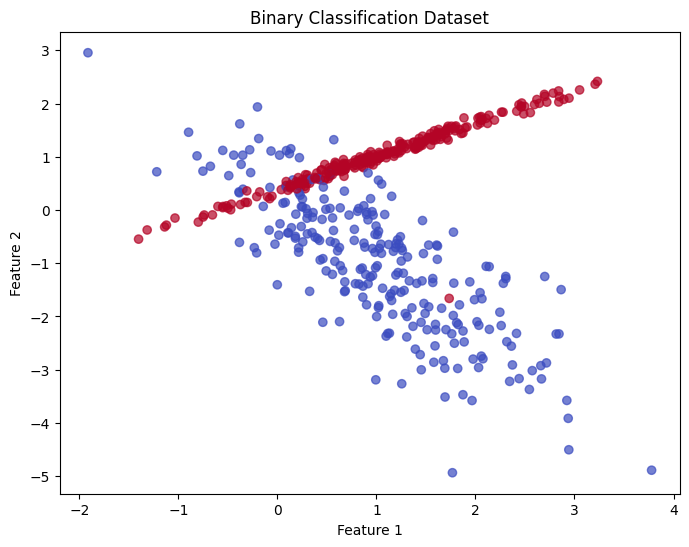

In [5]:
#Visualize the dataset
plt.figure(figsize=(8, 6))

plt.scatter(
    df["Feature_1"],
    df["Feature_2"],
    c=df["Target"],
    cmap="coolwarm",
    alpha=0.7
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.title("Binary Classification Dataset")

plt.show()

In [6]:
#Separate X and y
X = df[["Feature_1", "Feature_2"]]

y = df["Target"]

In [7]:
#Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 400
Testing samples: 100


In [8]:
#Create the Logistic Regression model
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression())
])

In [9]:
#Train the model
model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('logistic', LogisticRegression())])

In [10]:
#Understand model coefficients
logistic_model = model.named_steps["logistic"]

print("Intercept:", logistic_model.intercept_)

print("Coefficients:", logistic_model.coef_)

Intercept: [-0.31549153]
Coefficients: [[0.2385118  2.99758357]]


In [11]:
#Generate class predictions
y_pred = model.predict(X_test)

print("Actual values:")
print(y_test.values[:10])

print("\nPredicted values:")
print(y_pred[:10])

Actual values:
[1 0 0 1 1 1 1 0 0 0]

Predicted values:
[1 0 0 1 1 1 1 1 0 0]


In [12]:
#Generate probability predictions
y_probability = model.predict_proba(X_test)

print(y_probability[:10])

probability_df = pd.DataFrame({
    "Actual_Class": y_test.values,
    "Probability_Class_0": y_probability[:, 0],
    "Probability_Class_1": y_probability[:, 1],
    "Predicted_Class": y_pred
})

probability_df.head(10)

[[0.25388916 0.74611084]
 [0.99751554 0.00248446]
 [0.99446889 0.00553111]
 [0.29900545 0.70099455]
 [0.06994537 0.93005463]
 [0.02153611 0.97846389]
 [0.23218106 0.76781894]
 [0.21371815 0.78628185]
 [0.99144759 0.00855241]
 [0.92079908 0.07920092]]


,Actual_Class,Probability_Class_0,Probability_Class_1,Predicted_Class
0,1,0.253889,0.746111,1
1,0,0.997516,0.002484,0
2,0,0.994469,0.005531,0
3,1,0.299005,0.700995,1
4,1,0.069945,0.930055,1
5,1,0.021536,0.978464,1
6,1,0.232181,0.767819,1
7,0,0.213718,0.786282,1
8,0,0.991448,0.008552,0
9,0,0.920799,0.079201,0


In [13]:
#Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

#Calculate Log Loss:
loss = log_loss(y_test, y_probability)

print("Log Loss:", loss)

Accuracy: 0.89
Log Loss: 0.31325693207454125


[[42  8]
 [ 3 47]]


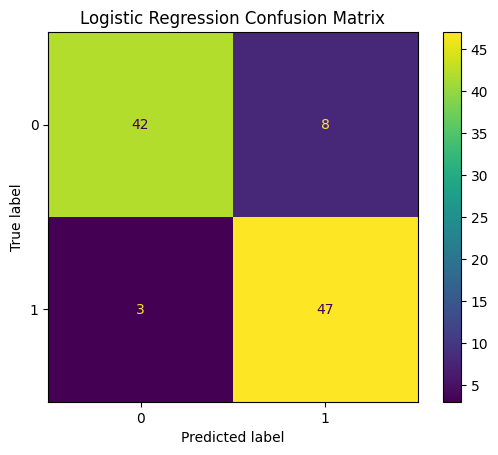

In [14]:
#Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print(cm)

#Visualize it:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [15]:
#Classification Report
print(
    classification_report(y_test, y_pred)
)

              precision    recall  f1-score   support

           0       0.93      0.84      0.88        50
           1       0.85      0.94      0.90        50

    accuracy                           0.89       100
   macro avg       0.89      0.89      0.89       100
weighted avg       0.89      0.89      0.89       100



In [16]:
#Experiment with the decision threshold
#Let's experiment with 0.3, 0.5 and 0.7.
probabilities = model.predict_proba(X_test)[:, 1]

thresholds = [0.3, 0.5, 0.7]

for threshold in thresholds:

    predictions = (
        probabilities >= threshold
    ).astype(int)

    print("\nThreshold:", threshold)

    print(
        "Accuracy:",
        accuracy_score(y_test, predictions)
    )

    print(
        "Confusion Matrix:\n",
        confusion_matrix(y_test, predictions)
    )


Threshold: 0.3
Accuracy: 0.82
Confusion Matrix:
 [[32 18]
 [ 0 50]]

Threshold: 0.5
Accuracy: 0.89
Confusion Matrix:
 [[42  8]
 [ 3 47]]

Threshold: 0.7
Accuracy: 0.83
Confusion Matrix:
 [[45  5]
 [12 38]]
